# Autos usados: predicción de precios y recomendaciones

## Pregunta del trabajo
¿Qué tan bien podemos estimar el precio publicado de un auto con sus características? Una vez evaluado el modelo, ¿cómo mostramos opciones que respeten presupuesto, plazas y preferencias?

El precio se predice con aprendizaje supervisado. La recomendación agrega filtros y un puntaje configurable; no afirmamos haber aprendido los gustos de una persona sin datos de usuarios.

Usamos `car details v4.csv`, de Vehicle dataset (Nehal Birla, Kaggle), con 2.059 registros y 20 columnas. Es un mercado de India, no de Argentina. El campo Price se conserva en sus unidades originales; falta corroborar la moneda en documentación del archivo. No se convierten precios ni se interpretan como cotizaciones vigentes. El CSV argentino queda como piloto, sin mezclarse con estos datos.

Fuente: https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho . Metadata y licencia del proveedor en `docs/dataset_metadata.json`. La actualización del paquete no equivale a fecha de cada aviso.

## Resultado de esta ejecución
k-NN, con k=5 y pesos por distancia, fue elegido por el MAE de validación cruzada. En los 413 avisos de test obtuvo R² = 0,744 y un MAE aproximadamente 68,4% menor que el baseline de mediana. Esto no significa “74,4% de aciertos” ni valida la utilidad del ranking. Los mayores errores aparecen en algunos autos de precio alto.

El dataset principal cumple el mínimo de columnas y permite trabajar todas las etapas requeridas. Quedan pendientes la confirmación documental de la moneda, la revisión del instructor y la discusión del grupo. Este notebook es una primera versión funcional, no una entrega final validada.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.autos import limpiar,evaluar,recomendar
sns.set_theme(style='whitegrid',context='notebook')
plt.rcParams.update({'figure.figsize':(10,5),'axes.spines.top':False,'axes.spines.right':False})
OUT=ROOT/'resultados';OUT.mkdir(exist_ok=True)
raw=pd.read_csv(ROOT/'data/raw/car_details_v4.csv')
print('Filas y columnas:',raw.shape)
display(raw.head())

Filas y columnas: (2059, 20)


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


## 1. Calidad de los datos
Una fila representa un aviso del dataset, no una venta confirmada. Revisamos tipos, nulos, duplicados y valores incompatibles con el significado de las variables. Los valores altos de precio o kilometraje no se eliminan por ser extremos: pueden corresponder a vehículos reales.

Los textos de motor y potencia incluyen unidades. Extraemos la primera cifra; el torque queda fuera del modelo porque combina magnitud y régimen. La ficha original y los campos originales permanecen disponibles. Los faltantes se imputan dentro de cada partición de entrenamiento, nunca antes de evaluar.

In [2]:
calidad=pd.DataFrame({'tipo':raw.dtypes.astype(str),'nulos':raw.isna().sum(),'porcentaje_nulos':raw.isna().mean()*100,'valores_distintos':raw.nunique()})
display(calidad)
print('Duplicados exactos:',raw.duplicated().sum())
datos=limpiar(raw)
print('Filas conservadas:',len(datos),'Excluidas:',len(raw)-len(datos))
display(datos[['Price','Year','Kilometer','engine_cc','power_bhp','Seating Capacity']].describe().round(2))
calidad.to_csv(OUT/'calidad.csv')

,tipo,nulos,porcentaje_nulos,valores_distintos
Make,str,0,0.000000,33
Model,str,0,0.000000,1050
Price,int64,0,0.000000,619
Year,int64,0,0.000000,22
Kilometer,int64,0,0.000000,847
Fuel Type,str,0,0.000000,9
Transmission,str,0,0.000000,2
Location,str,0,0.000000,77
Color,str,0,0.000000,17
Owner,str,0,0.000000,6


Duplicados exactos: 0
Filas conservadas: 2059 Excluidas: 0


,Price,Year,Kilometer,engine_cc,power_bhp,Seating Capacity
count,2059.00,2059.00,2059.00,1979.00,1979.00,1995.00
mean,1702991.70,2016.43,54224.71,1692.58,129.61,5.31
std,2419880.64,3.36,57361.72,643.74,65.07,0.82
min,49000.00,1988.00,0.00,624.00,35.00,2.00
25%,484999.00,2014.00,29000.00,1197.00,83.00,5.00
50%,825000.00,2017.00,50000.00,1498.00,116.00,5.00
75%,1925000.00,2019.00,72000.00,1995.00,171.00,5.00
max,35000000.00,2022.00,2000000.00,6592.00,660.00,8.00


## 2. Exploración univariada
Usamos histogramas para ver la forma de las distribuciones y boxplots para localizar colas y posibles extremos. Una escala logarítmica permite ver precios de distinto orden de magnitud; no cambia los valores que se usan al evaluar el error.

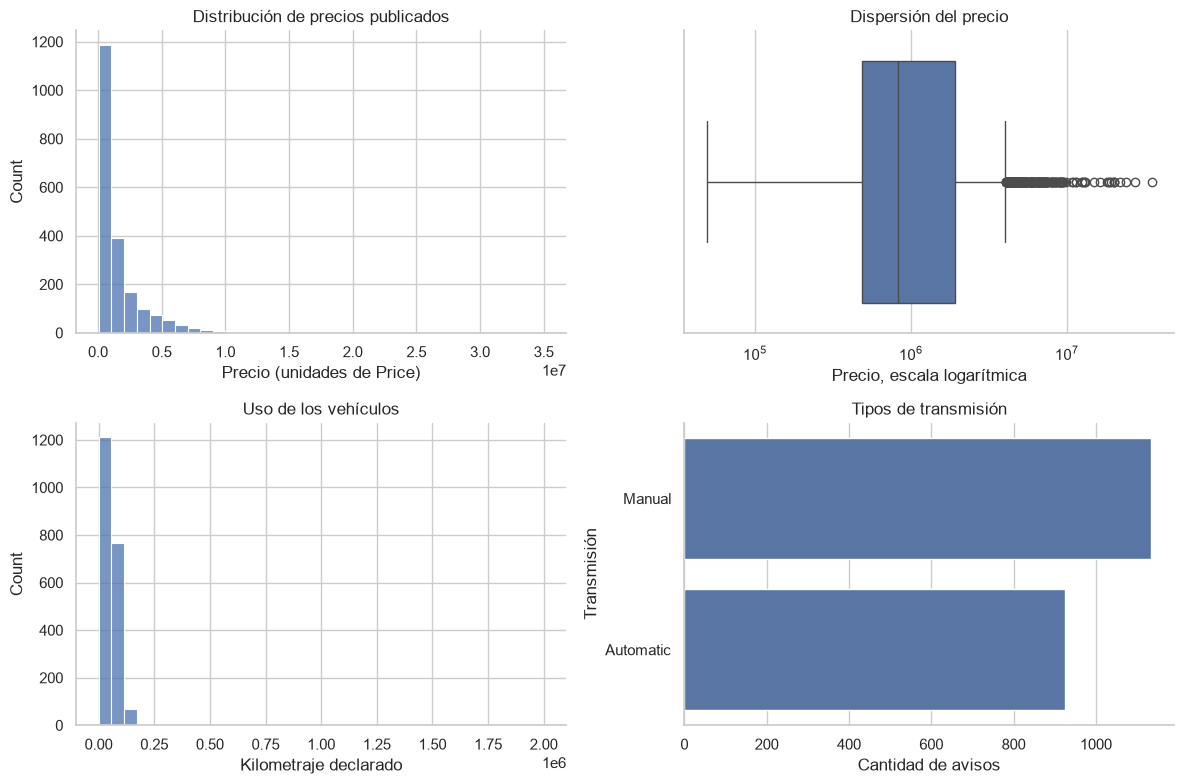

In [3]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
sns.histplot(datos.Price,bins=35,ax=axes[0,0]);axes[0,0].set(xlabel='Precio (unidades de Price)',title='Distribución de precios publicados')
sns.boxplot(x=datos.Price,ax=axes[0,1]);axes[0,1].set(xscale='log',xlabel='Precio, escala logarítmica',title='Dispersión del precio')
sns.histplot(datos.Kilometer,bins=35,ax=axes[1,0]);axes[1,0].set(xlabel='Kilometraje declarado',title='Uso de los vehículos')
sns.countplot(y=datos.Transmission,ax=axes[1,1]);axes[1,1].set(xlabel='Cantidad de avisos',ylabel='Transmisión',title='Tipos de transmisión')
fig.tight_layout();fig.savefig(OUT/'01_univariado.png',dpi=150);plt.show()

## 3. Relaciones y agregaciones
El año es el año del vehículo, no la fecha del aviso. Por eso el gráfico por año es una comparación de cohortes y no una serie de evolución de precios. La consigna pide serie temporal si hay fechas; este archivo no aporta una fecha de observación.

La correlación describe asociación lineal; no demuestra causalidad. Las medianas por marca también reflejan diferencias de modelos, antigüedad y equipamiento.

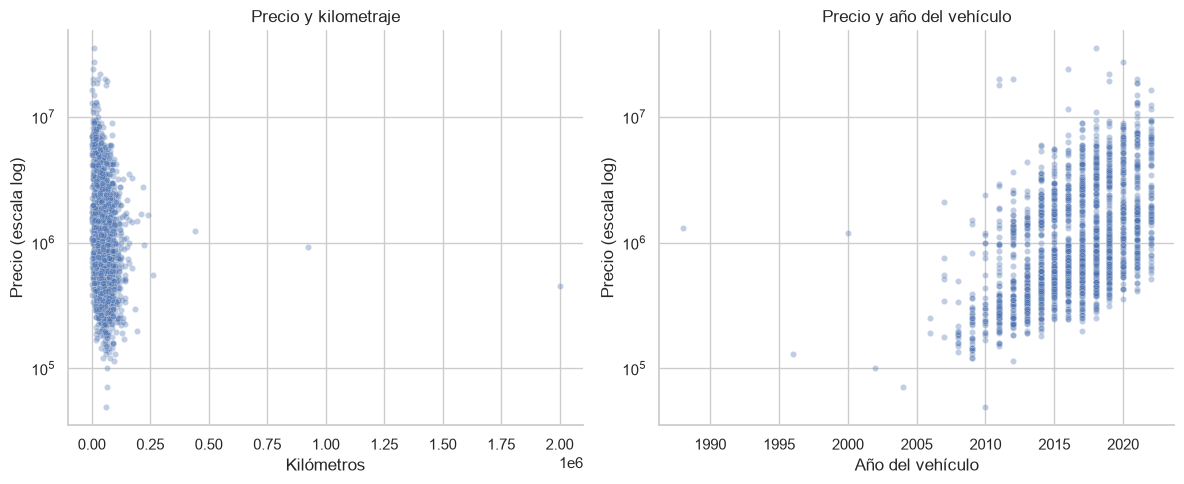

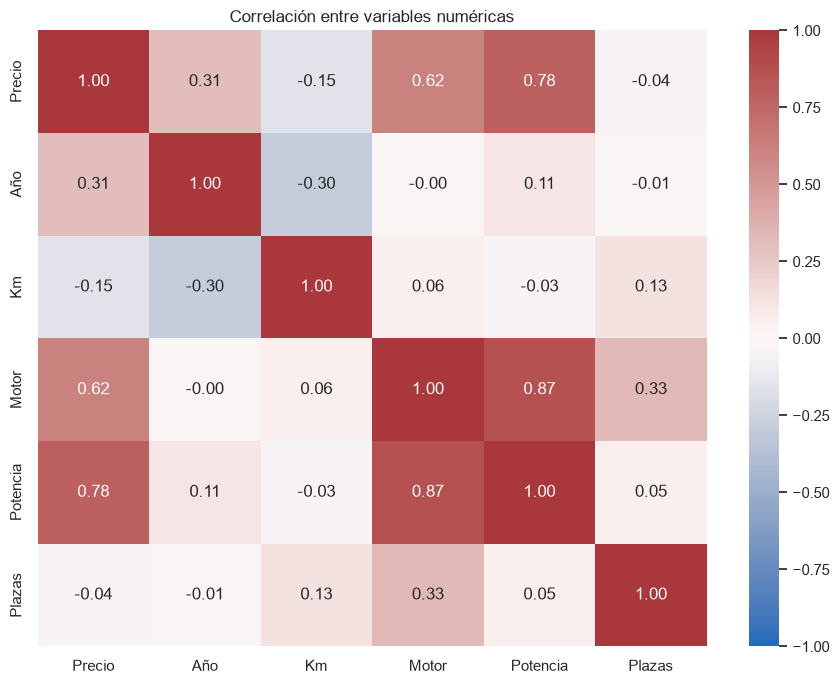

,avisos,precio_mediano
Make,,
Maruti Suzuki,440,525000.0
Hyundai,349,595000.0
Mercedes-Benz,171,3850000.0
Honda,158,577500.0
Toyota,132,1589500.0
Audi,127,2380000.0
BMW,121,3550000.0
Mahindra,119,955000.0
Tata,57,795000.0


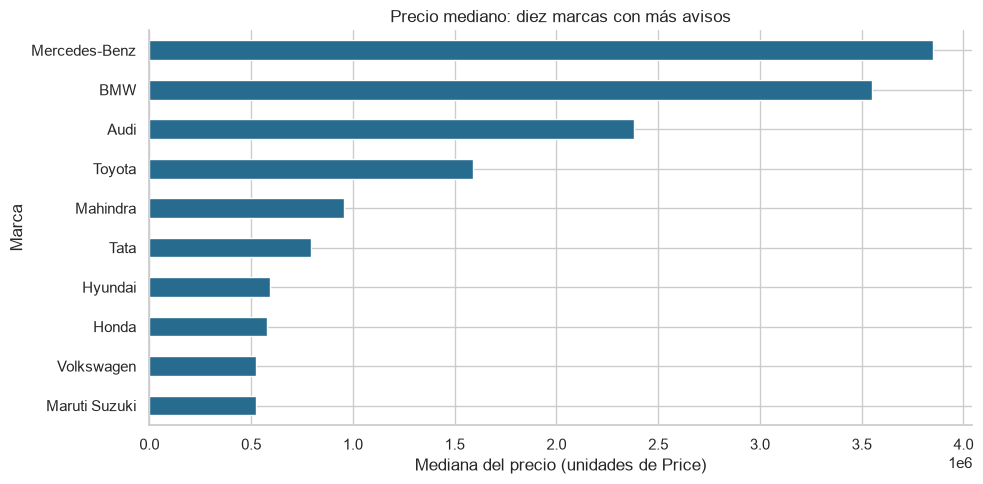

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.scatterplot(data=datos,x='Kilometer',y='Price',alpha=.35,s=20,ax=axes[0]);axes[0].set(yscale='log',xlabel='Kilómetros',ylabel='Precio (escala log)',title='Precio y kilometraje')
sns.scatterplot(data=datos,x='Year',y='Price',alpha=.35,s=20,ax=axes[1]);axes[1].set(yscale='log',xlabel='Año del vehículo',ylabel='Precio (escala log)',title='Precio y año del vehículo')
fig.tight_layout();fig.savefig(OUT/'02_relaciones.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(9,7))
sns.heatmap(datos[['Price','Year','Kilometer','engine_cc','power_bhp','Seating Capacity']].rename(columns={'Price':'Precio','Year':'Año','Kilometer':'Km','engine_cc':'Motor','power_bhp':'Potencia','Seating Capacity':'Plazas'}).corr(),annot=True,fmt='.2f',cmap='vlag',vmin=-1,vmax=1,ax=ax)
ax.set_title('Correlación entre variables numéricas');fig.tight_layout();fig.savefig(OUT/'03_correlacion.png',dpi=150);plt.show()
marcas=datos.groupby('Make').agg(avisos=('Price','size'),precio_mediano=('Price','median')).sort_values('avisos',ascending=False).head(10)
display(marcas)
fig,ax=plt.subplots(figsize=(10,5));marcas.sort_values('precio_mediano').precio_mediano.plot.barh(ax=ax,color='#276b8e')
ax.set(xlabel='Mediana del precio (unidades de Price)',ylabel='Marca',title='Precio mediano: diez marcas con más avisos')
fig.tight_layout();fig.savefig(OUT/'04_marcas.png',dpi=150);plt.show()

### Lectura del EDA
La distribución de precios tiene una cola a la derecha: pocos avisos muy caros conviven con una mayoría de valores menores. El kilometraje también presenta extremos. Conservamos esos registros mientras no exista evidencia de error de carga; quitarlos solo para mejorar las métricas cambiaría el problema.

La potencia muestra una asociación positiva con el precio en esta muestra. Las diferencias por marca no son un efecto aislado de la marca: también cambian los modelos y el equipamiento. El análisis es descriptivo y no permite afirmar causalidad.

## 4. Modelado sin usar el test para elegir
Definimos y = Price. X incluye antigüedad mediante año, kilometraje, especificaciones y categorías disponibles. No incluimos el precio en X, ni un identificador del aviso.

Reservamos aproximadamente el 20% por grupos de marca, versión y año. El tamaño exacto depende de esos grupos. Usamos cinco particiones agrupadas dentro de train para comparar baseline de mediana, regresión lineal y k-NN. El MAE de validación decide el modelo; después se mide el test una sola vez. La imputación, la codificación de categorías y el escalado se ajustan dentro del Pipeline.

MAE indica el error absoluto típico medio; RMSE penaliza más los errores grandes; R² compara contra predecir la media. R² puede ser negativo. No garantizamos un porcentaje de precisión antes de evaluar.

In [5]:
metricas,catalogo,detalle=evaluar(datos)
display(metricas.round(3))
print(json.dumps(detalle,ensure_ascii=False,indent=2))
metricas.to_csv(OUT/'metricas.csv',index=False)
catalogo.to_csv(OUT/'catalogo_evaluacion.csv',index=False)
(OUT/'particiones.json').write_text(json.dumps(detalle,ensure_ascii=False,indent=2))

,modelo,MAE_CV,MAE_test,RMSE_test,R2_test,elegido_por_CV
0,Baseline mediana,1216742.535,1215824.477,2902498.564,-0.078,False
1,Regresión lineal,635963.873,717155.158,1832242.314,0.571,False
2,k-NN,390979.217,384351.284,1413494.516,0.744,True


{
  "modelo_elegido": "k-NN",
  "parametros": {
    "modelo__n_neighbors": 5,
    "modelo__weights": "distance"
  },
  "train": 1646,
  "test": 413,
  "grupos_train": 1272,
  "grupos_test": 319,
  "grupos_compartidos": 0
}


222

## 5. Inspección de errores
La tabla de test se usa para describir el resultado de los modelos ya definidos, no para seguir ajustándolos. Comparamos la predicción del ganador con el precio publicado y revisamos los errores grandes sin ocultarlos.

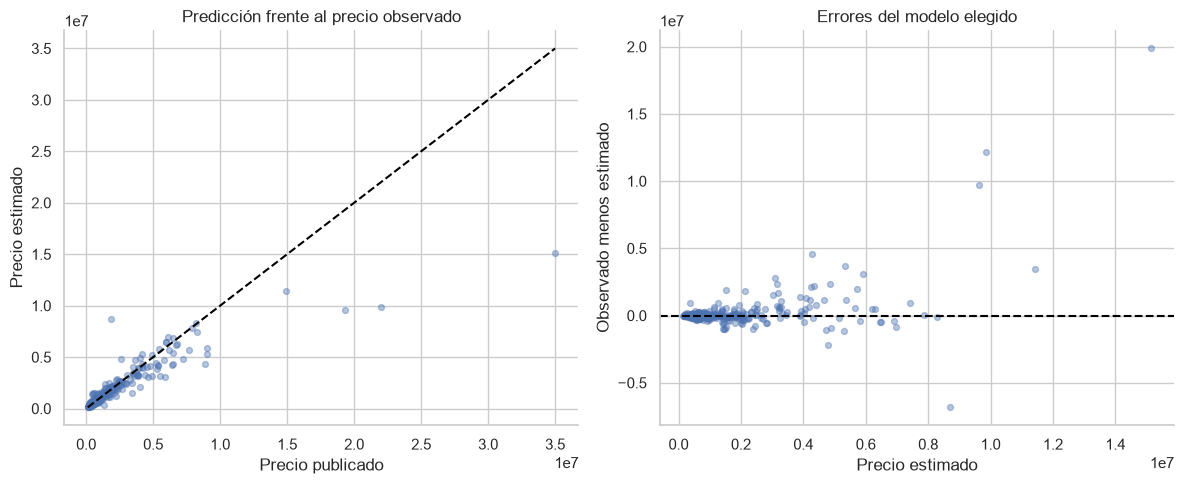

,Make,Model,Price,precio_estimado,error_absoluto
483,Ferrari,488 GTB,35000000,1.512958e+07,1.987042e+07
582,Land Rover,Range Rover 3.0 V6 Diesel Vogue,22000000,9.867481e+06,1.213252e+07
1313,Land Rover,Range Rover 3.0 V6 Diesel Vogue,19300000,9.625118e+06,9.674882e+06
1768,Mercedes-Benz,S-Class S 500,1875000,8.700938e+06,6.825938e+06
2032,Land Rover,Range Rover Velar 2.0 S Petrol 250,8900000,4.290898e+06,4.609102e+06
233,Maserati,Levante Diesel,9000000,5.341112e+06,3.658888e+06
1803,Porsche,Cayenne Base,14900000,1.143680e+07,3.463196e+06
1052,Porsche,Macan Base [2019-2020],9000000,5.908858e+06,3.091142e+06


In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(catalogo.Price,catalogo.precio_estimado,alpha=.4,s=18)
lim=[min(catalogo.Price.min(),catalogo.precio_estimado.min()),max(catalogo.Price.max(),catalogo.precio_estimado.max())]
axes[0].plot(lim,lim,color='black',linestyle='--');axes[0].set(xlabel='Precio publicado',ylabel='Precio estimado',title='Predicción frente al precio observado')
axes[1].scatter(catalogo.precio_estimado,catalogo.Price-catalogo.precio_estimado,alpha=.4,s=18)
axes[1].axhline(0,color='black',linestyle='--');axes[1].set(xlabel='Precio estimado',ylabel='Observado menos estimado',title='Errores del modelo elegido')
fig.tight_layout();fig.savefig(OUT/'05_errores.png',dpi=150);plt.show()
errores=catalogo.assign(error_absoluto=(catalogo.Price-catalogo.precio_estimado).abs()).sort_values('error_absoluto',ascending=False)
display(errores[['Make','Model','Price','precio_estimado','error_absoluto']].head(8))

## 6. Del modelo al recomendador
Primero se aplican condiciones obligatorias: presupuesto máximo y plazas mínimas, y opcionalmente transmisión, combustible, año mínimo y kilometraje máximo. Un dato faltante de plazas no acredita que el auto cumpla ese requisito.

Después calculamos un puntaje de precio, año y kilometraje, con pesos que suman uno. Menor precio, mayor año y menor kilometraje dan mayor puntaje. Las escalas se fijan respecto del catálogo antes de aplicar preferencias. La predicción se muestra como información adicional: una diferencia con el precio publicado no prueba que exista una oportunidad de compra.

Para esta demostración usamos solo avisos de test: el modelo no fue ajustado con su precio. El ranking es una regla explicable, no una probabilidad de satisfacción. Su utilidad requeriría evaluación con usuarios y no se mide con el R² del precio.

In [7]:
opciones=recomendar(catalogo,presupuesto=800000,plazas=5,caja='Manual',km_max=100000,pesos=(.3,.4,.3))
display(opciones[['Make','Model','Price','precio_estimado','puntaje','explicacion']])
assert opciones.Price.le(800000).all()
assert opciones['Seating Capacity'].ge(5).all()
assert opciones.Kilometer.le(100000).all()
assert recomendar(catalogo,1).empty
try:
    recomendar(catalogo,-1)
    raise AssertionError('Se aceptó presupuesto negativo')
except ValueError:
    pass
print('Comprobados: filtros de presupuesto, plazas, kilometraje, resultado vacío y presupuesto inválido.')

,Make,Model,Price,precio_estimado,puntaje,explicacion
1744,Renault,Kwid RXT [2015-2019],250000,348364.594439,0.842626,"5 plazas; Manual; Petrol; año 2017; 32,000 km"
739,Datsun,Go T (O),270000,310918.105420,0.835876,"5 plazas; Manual; Petrol; año 2017; 27,000 km"
881,Maruti Suzuki,Eeco 5 STR WITH A/C+HTR [2019-2020],328000,446906.875107,0.825920,"5 plazas; Manual; Petrol; año 2018; 26,807 km"
915,Renault,Kwid RXT [2015-2019],315000,335256.247786,0.820725,"5 plazas; Manual; Petrol; año 2017; 15,507 km"
923,Renault,Kwid RXT [2015-2019],315000,335256.247786,0.820725,"5 plazas; Manual; Petrol; año 2017; 15,507 km"


Comprobados: filtros de presupuesto, plazas, kilometraje, resultado vacío y presupuesto inválido.


## 7. Conclusiones y defensa
La siguiente síntesis se calcula con los resultados ejecutados. Si el baseline gana, debe decirse: disponer de un algoritmo más complejo no garantiza mejorar la predicción.

Límites del trabajo: muestra de avisos de India, precios publicados y no ventas cerradas, sin fecha individual de captura, sin historial de mantenimiento ni medida de seguridad. La moneda de Price necesita corroboración documental antes de mostrar un símbolo monetario. Las predicciones negativas, si aparecen, indican una limitación del modelo lineal y no se interpretan como precios válidos. No se usan para habilitar compras ni como asesoramiento comercial.

Para la defensa: explicar por qué separar grupos, por qué escalar k-NN, cómo evitar fuga de información, por qué una serie por año del vehículo no es una serie de mercado y por qué evaluar precios no valida el ranking. Falta la revisión del dataset con el instructor sugerida en la consigna.

Referencias de la cursada: PY-002, P018–P034 (consigna); PY-031 (calidad); PY-037 y PY-038 (estadística y correlación); PY-039 (agregaciones); PY-044 y PY-045 (gráficos); PY-052, C016/C039/C050/C052 (split, métricas, validación y búsqueda). Repositorio de clase: https://github.com/UADE-Python-Data-Science/583433_repo_oficial/tree/4589c4da36188bab5badab791f7f70b344a401cd .

In [8]:
elegido=metricas.loc[metricas.elegido_por_CV].iloc[0]
base=metricas.loc[metricas.modelo.eq('Baseline mediana')].iloc[0]
print(f"Modelo elegido con validación: {elegido.modelo}.")
print(f"Test: MAE {elegido.MAE_test:,.0f}; RMSE {elegido.RMSE_test:,.0f}; R² {elegido.R2_test:.3f}.")
print(f"Cambio de MAE frente al baseline en test: {(1-elegido.MAE_test/base.MAE_test)*100:.1f}% (positivo significa menor error).")
print(f"Se usaron {detalle['train']} avisos para entrenar y {detalle['test']} para evaluar, sin grupos compartidos.")

Modelo elegido con validación: k-NN.
Test: MAE 384,351; RMSE 1,413,495; R² 0.744.
Cambio de MAE frente al baseline en test: 68.4% (positivo significa menor error).
Se usaron 1646 avisos para entrenar y 413 para evaluar, sin grupos compartidos.
